# code to extract metadata from my local pm3 archive   
**(run on LOCAL runtime)**

## connecting to local runtime (so finds folder)

In [ ]:
# CONNECTING TO LOCAL RUNTIME:
# get  backend URL used for authentication (copy resulting line of text with 2nd address):
# **RUN THIS IN CMD EACH SESSION**

# > [run in CMD]
py -m notebook --no-browser --NotebookApp.allow_origin="https://colab.research.google.com" --NotebookApp.allow_credentials=True --port=8888 --NotebookApp.port_retries=0

# > > copied 15/09/2026 (1st time connecting): http://127.0.0.1:8888/tree?token=8bd3ef3aa17fb46ec8e7d266943ce2936bee58d571328a5a  **CHANGES EACH TIME**


## import libraries to handle local folders, a progress bar (incase slow) and audio file metadata

In [ ]:
# for reading audio file metadata:
# [CMD]>>  py -m pip install mutagen   = OK


In [ ]:
# for incorporating progress bar
# [CMD]>>  py -m pip install tqdm   = OK

In [ ]:
from pathlib import Path
from mutagen import File
import pandas as pd
from tqdm import tqdm


## function to loop through local folder and extract data

In [ ]:
def extract_music_collection(main_folder_path):
  root_path = Path(main_folder_path)
  records = []

  mp3_files = list(root_path.rglob('*.mp3'))
  print(f'Found {len(mp3_files):,} MP3 files. Scanning local directory...')

  # Wrap the file list in tqdm for a live progress bar
  for file_path in tqdm(mp3_files, desc='Extracting Metadata'):
    folder_artist = file_path.parent.name
    title, artist, album, year, genre, duration = (
        None,
        None,
        None,
        None,
        None,
        None,
    )

    try:
      audio = File(file_path, easy=True)
      if audio is not None:
        title = audio.get('title', [None])[0]
        artist = audio.get('artist', [None])[0]
        album = audio.get('album', [None])[0]
        year = audio.get('date', [None])[0]
        genre = audio.get('genre', [None])[0]
        if hasattr(audio, 'info') and audio.info:
          duration = audio.info.length
    except Exception:
      continue

    records.append({
        'file_name': file_path.name,
        'folder_artist': folder_artist,
        'tag_artist': artist,
        'tag_title': title,
        'album': album,
        'year': year,
        'genre': genre,
        'duration_secs': duration,
        'file_path': str(file_path),
    })

  return pd.DataFrame(records)


## run the function on my local mp3 folder

In [ ]:
# path to folder: "C:\Users\DELL\Desktop\music_mp3_copied\iTunes Music"

df_mp3 = extract_music_collection(r"C:\Users\DELL\Desktop\music_mp3_copied\iTunes Music")

Found 2,255 MP3 files. Scanning local directory...


Extracting Metadata: 100%|██████████| 2255/2255 [00:05<00:00, 411.69it/s]


## final data frame created

In [ ]:
df_mp3.info()

<class 'pandas.DataFrame'>
RangeIndex: 1892 entries, 0 to 1891
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   file_name      1892 non-null   str    
 1   folder_artist  1892 non-null   str    
 2   tag_artist     1765 non-null   str    
 3   tag_title      1749 non-null   str    
 4   album          1591 non-null   str    
 5   year           1066 non-null   str    
 6   genre          1430 non-null   str    
 7   duration_secs  1892 non-null   float64
 8   file_path      1892 non-null   str    
dtypes: float64(1), str(8)
memory usage: 133.2 KB


In [ ]:
df_mp3.head(20)

,file_name,folder_artist,tag_artist,tag_title,album,year,genre,duration_secs,file_path
0,09 Brazilectro (DJ Git Hyper Mix).mp3,Latin Travels,Zuco 103,Brazilectro (DJ Git Hyper Mix),Latin Travels,NaN,electro,314.283625,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
1,15 Treasure.mp3,Nu Brazil,Zuco 103,Treasure,Nu Brazil,NaN,Nu Brasil,52.782187,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
2,02 Maracatu Atomico (Bossacucanova mix).mp3,O Outro Lado Of The Other Side,Zuco 103,Maracatu Atomico (Bossacucanova mix),O Outro Lado Of The Other Side,NaN,General World,338.581062,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
3,01 Humana.mp3,Outro Lado,Zuco 103,Humana,Outro Lado,2000,Latin,283.245708,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
4,08 Fome Total (Funky Lowlives Dub.mp3,Recline_ A Six Degrees Collect,Zuco 103,Fome Total (Funky Lowlives Dub,Recline: A Six Degrees Collect,NaN,Other,316.656313,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
5,07 Whaa!.mp3,Whaa!,Zuco 103,Whaa!,Whaa!,2005,World,261.308167,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
6,12 It's A Woman's World.mp3,Whaa!,Zuco 103,It's A Woman's World,Whaa!,2005,World,199.215125,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
7,08 Crazy Pills.mp3,Zoolander,Zoolander quotes,08 Crazy Pills,Zoolander,NaN,NaN,2.784000,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
8,11 Serious Trouble.mp3,As Heard on Radio Soulwax pt. 2,Zongamin,Serious Trouble,As Heard on Radio Soulwax pt. 2,NaN,Rap,99.265250,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
9,10 Spiral.mp3,Electro3b,Zongamin,Spiral,Electro3b,2002,Electronica,240.927347,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...


In [ ]:
# See how many tracks are missing tags vs successfully tagged
print("\nMissing values per column:")
print(df_mp3.isnull().sum())


Missing values per column:
file_name          0
folder_artist      0
tag_artist       127
tag_title        143
album            301
year             826
genre            462
duration_secs      0
file_path          0
dtype: int64


In [ ]:
display(df_mp3.loc[df_mp3['tag_artist'].isnull()])


,file_name,folder_artist,tag_artist,tag_title,album,year,genre,duration_secs,file_path
54,Ojos de brujo - Entre Dos Aguas.mp3,Unknown Album,NaN,NaN,NaN,NaN,NaN,360.306000,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
355,Dragula (Hot Rod Herman Remix).mp3,The Matrix Soundtrack,NaN,NaN,NaN,NaN,NaN,150.609070,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
479,Wake Up.mp3,The Matrix Soundtrack,NaN,NaN,NaN,NaN,NaN,197.708118,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
596,Animals - Album.mp3,Complete Entire Full (Album),NaN,NaN,NaN,NaN,NaN,910.988980,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
1280,Eat Static - Dream Snatcher(Gran Turismo 4 Sou...,Álbum desconocido,NaN,NaN,NaN,NaN,Other,181.350063,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
...,...,...,...,...,...,...,...,...,...
1774,TV Themes - Mission Impossible.mp3,Álbum desconocido,NaN,NaN,NaN,NaN,NaN,55.509937,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
1775,tv themes - the a-team.mp3.mp3,Álbum desconocido,NaN,tv themes - the a-team.mp3,NaN,NaN,NaN,97.920000,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
1776,wayne's world - Garth's Drum Solo 1.mp3,Álbum desconocido,NaN,wayne's world - Garth's Drum Solo,NaN,NaN,Other,26.888000,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
1777,wayne's world - Garth's Drum Solo.mp3,Álbum desconocido,NaN,wayne's world - Garth's Drum Solo,NaN,NaN,NaN,2.351938,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...


In [ ]:
display(df_mp3.loc[df_mp3['tag_artist'] == 'Pink Floyd'])

,file_name,folder_artist,tag_artist,tag_title,album,year,genre,duration_secs,file_path
599,Pink Floyd - Wish You Were Here (Entire Album)...,Álbum desconocido,Pink Floyd,NaN,NaN,NaN,Blues,2668.2045,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
600,01 piper at the gates of dawn - Album.mp3,Piper at the Gates of Dawn,Pink Floyd,piper at the gates of dawn - Album,Piper at the Gates of Dawn,1967,Rock & Roll,2516.3320,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...


## can use the backup folder_artist and file_name to try and fill some missing values...

In [ ]:
# Create a clean artist column using ID3 tags, falling back to the folder name
df_mp3['artist_backup'] = df_mp3['tag_artist'].fillna(df_mp3['folder_artist'])

# Create a clean title column using ID3 tags, falling back to the file name
df_mp3['title_backup'] = df_mp3['tag_title'].fillna(df_mp3['file_name'].str.replace('.mp3', '', case=False))

# Check the results
print('Remaining missing artists:', df_mp3['artist_backup'].isnull().sum())
print('Remaining missing titles:', df_mp3['title_backup'].isnull().sum())

Remaining missing artists: 0
Remaining missing titles: 0


In [ ]:
display(df_mp3.loc[df_mp3['tag_artist'].isnull()].head(25))

,file_name,folder_artist,tag_artist,tag_title,album,year,genre,duration_secs,file_path,artist_backup,title_backup
54,Ojos de brujo - Entre Dos Aguas.mp3,Unknown Album,NaN,NaN,NaN,NaN,NaN,360.306000,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...,Unknown Album,Ojos de brujo - Entre Dos Aguas
355,Dragula (Hot Rod Herman Remix).mp3,The Matrix Soundtrack,NaN,NaN,NaN,NaN,NaN,150.609070,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...,The Matrix Soundtrack,Dragula (Hot Rod Herman Remix)
479,Wake Up.mp3,The Matrix Soundtrack,NaN,NaN,NaN,NaN,NaN,197.708118,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...,The Matrix Soundtrack,Wake Up
596,Animals - Album.mp3,Complete Entire Full (Album),NaN,NaN,NaN,NaN,NaN,910.988980,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...,Complete Entire Full (Album),Animals - Album
1280,Eat Static - Dream Snatcher(Gran Turismo 4 Sou...,Álbum desconocido,NaN,NaN,NaN,NaN,Other,181.350063,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...,Álbum desconocido,Eat Static - Dream Snatcher(Gran Turismo 4 Sou...
1653,Nine Inch Nails - Just Like You Imagined (300 ...,300,NaN,NaN,300,NaN,NaN,229.929792,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...,300,Nine Inch Nails - Just Like You Imagined (300 ...
1654,01 Pista 01.mp3,FAR EAST,NaN,Pista 01,FAR EAST,NaN,NaN,275.121667,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...,FAR EAST,Pista 01
1655,02 Pista 02.mp3,FAR EAST,NaN,Pista 02,FAR EAST,NaN,NaN,312.293917,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...,FAR EAST,Pista 02
1656,03 Pista 03.mp3,FAR EAST,NaN,Pista 03,FAR EAST,NaN,NaN,405.472667,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...,FAR EAST,Pista 03
1657,04 Pista 04.mp3,FAR EAST,NaN,Pista 04,FAR EAST,NaN,NaN,170.161667,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...,FAR EAST,Pista 04


## save a copy locally on laptop

In [ ]:
# SAVE AS CSV AGAIN LOCALLY!!

df_mp3.to_csv("C:\\Users\\DELL\\Desktop\\CODE\\IT_ACADEMY\\Sprint_13_PROJECT\\SPOTIFY_project\\mp3_dades_oct26\\df_mp3.csv", index=False)


## load cleaned up copy

In [ ]:
# load cleaned up copy:

mp3 = pd.read_csv("C:\\Users\\DELL\\Desktop\\CODE\\IT_ACADEMY\\Sprint_13_PROJECT\\SPOTIFY_project\\mp3_dades_oct26\\mp3_clean.csv")

In [ ]:
mp3.info()

<class 'pandas.DataFrame'>
RangeIndex: 1702 entries, 0 to 1701
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   file_name      1702 non-null   str    
 1   folder_artist  1701 non-null   str    
 2   tag_artist     1696 non-null   str    
 3   tag_title      1658 non-null   str    
 4   album          1497 non-null   str    
 5   year           1017 non-null   str    
 6   genre          1135 non-null   str    
 7   duration_secs  1702 non-null   float64
 8   file_path      1702 non-null   str    
dtypes: float64(1), str(8)
memory usage: 119.8 KB


In [ ]:
length = mp3['duration_secs'].sum()
print(f"Have {(length/60)/60} hours of music in my mp3 archive ({(length/60)/60/24} days)")

Have 7608.419811810358 hours of music in my mp3 archive (317.0174921587649 days)


In [ ]:
mp3['duration_secs'] = mp3['duration_secs'].astype(float)

In [ ]:
mp3.loc[mp3['album'] == 'Breezeblock']

,file_name,folder_artist,tag_artist,tag_title,album,year,genre,duration_secs,file_path
35,Essential Selection 8_24_01.mp3,~mixes,Chemical Brothers,Essential Selection 8/24/01,Breezeblock,2001,Electronic,3521.833917,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
323,Breezeblock - Talvin Singh.mp3,Breezeblock,Talvin Singh,Breezeblock - Talvin Singh,Breezeblock,NaN,Dance,3602.084750,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
324,Breezeblock-Ninja Tune DJs.mp3,Ninja Tune Djs,Breezeblock,Breezeblock-Ninja Tune DJs,Breezeblock,NaN,Ninja,676.869125,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
325,Breezeblock - Thievery Corporation.mp3,Breezeblock,Thievery Corporation,Breezeblock - Thievery Corporation,Breezeblock,2002,NaN,1822.362312,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...


In [ ]:
mp3['duration_secs'].describe()

count    1.702000e+03
mean     1.609301e+04
std      8.802495e+04
min      2.528437e+00
25%      1.910865e+02
50%      2.465123e+02
75%      3.255641e+02
max      2.516332e+06
Name: duration_secs, dtype: float64

In [ ]:
# Show the tracks with the longest durations
print(
    df_mp3.sort_values(by='duration_secs', ascending=False)[
        ['file_name', 'folder_artist', 'duration_secs']
    ].head(10)
)

                                              file_name  \
1763  S-P-U-N-K 05.02 (Röyksopp, Märtini Brös, Steve...   
1739  Liquid Acid - Music Is Living (feat. Kruder & ...   
1764  St Germain - Cafe Del Mar- Finest Electro Jazz...   
480                               Woodstock Set.mp3.mp3   
1469                             THDDB mix 16-03-02.mp3   
1738  Liquid Acid - blue notes `n smoke (dub, tripho...   
870               01 Michel Thomas Greek foundation.mp3   
1671  01 01 Buena Vista Social Club - Salsa - Full A...   
256                      Breezeblock - Talvin Singh.mp3   
1473                    Essential Selection 8_24_01.mp3   

                       folder_artist  duration_secs  
1763               Álbum desconocido    4478.738062  
1739               Álbum desconocido    4335.725750  
1764               Álbum desconocido    4250.671000  
480                     Woodstock 99    4019.782688  
1469               Álbum desconocido    3962.049417  
1738               Álbum d

In [ ]:
# Create a subset excluding long-form DJ sets and full albums (> 15 minutes)
mp3_songs_only = mp3[mp3['duration_secs'] <= 900]

# Check the new stats for regular songs
print(mp3_songs_only['duration_secs'].describe())



count    1575.000000
mean      247.106851
std       112.035168
min         2.528437
25%       185.199104
50%       237.741633
75%       298.949069
max       723.808813
Name: duration_secs, dtype: float64


In [ ]:
songs_only_length = mp3_songs_only['duration_secs'].sum()
print(f"Have {(songs_only_length/60)/60} hours of music (excluding albumwraps) in my mp3 archive ({((songs_only_length/60)/60)/24} days)")


Have 108.10924744388541 hours of music (excluding albumwraps) in my mp3 archive (4.504551976828559 days)


## fixing duration data errors (tracks that are not albums)

In [ ]:
# its detecting way too many:
long_tracks = mp3[mp3['duration_secs'] >= 900]

long_tracks.count()

file_name        127
folder_artist    126
tag_artist       127
tag_title        118
album             98
year              53
genre             67
duration_secs    127
file_path        127
dtype: int64

In [ ]:
# 1. See how many tracks have absurdly long durations (> 5.5h / 20000 seconds)
absurdly_long = mp3[mp3['duration_secs'] > 20000]
print(f'Found {len(absurdly_long)} tracks with really long lengths (>5.5h).')
print(absurdly_long[['file_name', 'folder_artist', 'tag_artist', 'duration_secs']])


Found 96 tracks with really long lengths (>5.5h).
                                      file_name      folder_artist  \
4                  05 - Muse - Plug_in_baby.mp3               Muse   
11                      Muse - Plug_in_baby.mp3               Muse   
27              its the thought that counts.mp3              -web-   
196           03 Please...Don't be yourself.mp3     Any Minute Now   
213   09 Roots Manuva - Next Type Of Motion.mp3       Back to Mine   
...                                         ...                ...   
1656                01 Hands Up For Detroit.mp3  Álbum desconocido   
1663        Ojos de brujo - Entre Dos Aguas.mp3      Unknown Album   
1664                    Trainspotting Theme.mp3  Álbum desconocido   
1675                        01 Earth Linger.mp3  Álbum desconocido   
1691                    01 - Sunday Morning.mp3  Álbum desconocido   

                  tag_artist  duration_secs  
4                       Muse       220442.0  
11               

In [ ]:
# remaining 'long' tracks (longest 40))
longest_40 = mp3.sort_values(by = 'duration_secs', ascending = False).head(40)
print(f"longest 40 tracks remaining...")
display(longest_40[['file_name', 'folder_artist', 'tag_artist', 'duration_secs']])

longest 40 tracks remaining...


,file_name,folder_artist,tag_artist,duration_secs
1682,"S-P-U-N-K 05.02 (Röyksopp, Märtini Brös, Steve...",Álbum desconocido,"S-P-U-N-K 05.02 (Röyksopp, Märtini Brös, Steve...",4478.738062
1653,Liquid Acid - Music Is Living (feat. Kruder & ...,Álbum desconocido,Liquid Acid,4335.725750
1466,Woodstock Set.mp3.mp3,Woodstock 99,Rage Against The Machine,4019.782688
1208,THDDB mix 16-03-02.mp3,Álbum desconocido,chicco,3962.049417
1565,"Liquid Acid - blue notes `n smoke (dub, tripho...",Álbum desconocido,Liquid Acid,3817.369550
857,01 Michel Thomas Greek foundation.mp3,Michel Thomas Greek Foundation,Michel Thomas,3650.191438
334,01 01 Buena Vista Social Club - Salsa - Full A...,Álbum desconocido,buena vista social club,3606.264312
323,Breezeblock - Talvin Singh.mp3,Breezeblock,Talvin Singh,3602.084750
35,Essential Selection 8_24_01.mp3,~mixes,Chemical Brothers,3521.833917
760,Liquid Acid - a Tribute to Female Singers (fea...,Álbum desconocido,Liquid Acid - a Tribute to Female Singers (dj ...,3520.339200


In [ ]:
# Only target absurdly high values (>20,000 seconds / ~5.5 hours)
bugged_mask = mp3['duration_secs'] > 20000

# divide values by 1000 for these masked rows
mp3.loc[bugged_mask, 'duration_secs'] = (mp3.loc[bugged_mask, 'duration_secs'] / 1000)

# Check describe again:
print(df_mp3['duration_secs'].describe())

count    1892.000000
mean      302.039015
std       411.906795
min         2.351938
25%       172.878922
50%       232.732875
75%       303.851360
max      4478.738062
Name: duration_secs, dtype: float64


In [ ]:
# check total length of mp3 archive again: = OK

length_cleaned = mp3['duration_secs'].sum()
print(f"Have {round((length_cleaned/60)/60, 2)} hours of music in my mp3 archive ({round((length_cleaned/60)/60/24, 2)} days)")

Have 138.78 hours of music in my mp3 archive (5.78 days)


## save again on laptop with duration fix implemented:



In [ ]:
# SAVE AS CSV AGAIN LOCALLY!!

mp3.to_csv("C:\\Users\\DELL\\Desktop\\CODE\\IT_ACADEMY\\Sprint_13_PROJECT\\SPOTIFY_project\\mp3_dades_oct26\\mp3_clean.csv", index=False)

# basic EDA on mp3 archive

In [ ]:
mp3.columns

Index(['file_name', 'folder_artist', 'tag_artist', 'tag_title', 'album',
       'year', 'genre', 'duration_secs', 'file_path'],
      dtype='str')

In [ ]:
# artists with most tracks saved:

top_artists_by_count = (mp3['tag_artist'].value_counts().reset_index(name='track_count'))
top_artists_by_count.columns = ['artist', 'track_count']

print('--- Top 10 artists by track count ---\n')
print(top_artists_by_count.head(10))

--- Top 10 Artists by Track Count ---
                  artist  track_count
0  Red Hot Chili Peppers           59
1                 Tricky           53
2                   Muse           45
3        Nine Inch Nails           38
4   Thievery Corporation           37
5               Le Tigre           32
6  The Real Tuesday Weld           25
7           ammoncontact           25
8                Orishas           23
9          Ojos de Brujo           23


In [ ]:
# artists with most minutes saved in archive:

top_artists_by_duration = (mp3.groupby('tag_artist')['duration_secs'].sum().reset_index(name='total_duration_secs'))
top_artists_by_duration['total_duration_hours'] = (top_artists_by_duration['total_duration_secs'] / 3600)

top_artists_by_duration = top_artists_by_duration.sort_values(by='total_duration_secs', ascending=False)

print('--- Top 10 artists by total duration of tracks saved in archive (hours) ---\n')
print(top_artists_by_duration.head(10))

--- Top 10 artists by total duration of tracks saved in archive (hours) ---

                tag_artist  total_duration_secs  total_duration_hours
390  Red Hot Chili Peppers         17625.929833              4.896092
478                 Tricky         12554.582350              3.487384
468   Thievery Corporation         11132.313250              3.092309
366             Pink Floyd         11040.827230              3.066896
330                   Muse         11015.372693              3.059826
336        Nine Inch Nails          9463.385091              2.628718
457  The Real Tuesday Weld          8964.719537              2.490200
279            Liquid Acid          8153.095300              2.264749
13              Amon Tobin          6160.328722              1.711202
54               Blockhead          5626.397086              1.562888


In [ ]:
# one hit wonder artists in my archive:

artist_counts = mp3['tag_artist'].value_counts()
single_track_artists = artist_counts[artist_counts == 1].index

df_single_tracks = mp3[mp3['tag_artist'].isin(single_track_artists)]

print(f'Total artists with only 1 track: {len(single_track_artists):,}')
print(df_single_tracks[['tag_artist', 'tag_title', 'file_name']].sort_values(by = 'tag_artist').head(10))

Total artists with only 1 track: 387
                           tag_artist                          tag_title  \
1605                       12 Monkeys                         Main Theme   
43           28 Days Later Soundtrack                            The End   
1255            A Forest Mighty Black                     06- Everything   
1222                    Abstract Rude         Something about this music   
156     Abstract Vibes 2 - More Vibes                         Old Artist   
337     Adani & Wolf Featuring Praful      Where Would I Be (Memòria Ver   
1598              Afro Cuban Allstars               Havanna Lounge music   
509                         Akmusique                          Cafe Noir   
1256                      Alex Gopher  08- Est-Ce Une Gopher Party, Baby   
212   Ali Farka Toure/Ali Farka Toure                           Mali Dje   

                                       file_name  
1605                              Main Theme.mp3  
43                      

In [ ]:
mp3.loc[mp3['year'] >= '2026']

,file_name,folder_artist,tag_artist,tag_title,album,year,genre,duration_secs,file_path
168,axe.mp3,Album,The Author,axe,Album,2935,Blues,23.01975,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...
169,The Title.mp3,Album,The Author,The Title,Album,2935,Blues,23.01975,C:\Users\DELL\Desktop\music_mp3_copied\iTunes ...


In [ ]:
# Drop rows where year is 2026 or later
mp3 = mp3[mp3['year'] < '2026'].copy()

In [ ]:
# earliest and most recent tracks (NB note all have 'year' value):

df_year_valid = mp3.dropna(subset=['year']).copy()
df_year_valid['year_num'] = pd.to_numeric(df_year_valid['year'].astype(str).str.extract(r'(\d{4})')[0], errors='coerce')
df_year_valid = df_year_valid.dropna(subset=['year_num'])
df_year_valid['year_num'] = df_year_valid['year_num'].astype(int)

earliest_year = df_year_valid['year_num'].min()
latest_year = df_year_valid['year_num'].max()

print(f'Earliest Year in Library: {earliest_year}')
print(df_year_valid[df_year_valid['year_num'] == earliest_year][['year_num', 'tag_artist', 'tag_title', 'album']].head(10))

print(f'\nMost Recent Year in Library: {latest_year}')
print(df_year_valid[df_year_valid['year_num'] == latest_year][['year_num', 'tag_artist', 'tag_title', 'album']].head(10))

Earliest Year in Library: 1931
     year_num  tag_artist           tag_title                    album
314      1931  Skip James  Devil Got My Woman  Blues Roots - 1930-1944

Most Recent Year in Library: 2009
     year_num     tag_artist                  tag_title  \
949      2009  Ojos de Brujo           02 02-NUEVA VIDA   
950      2009  Ojos de Brujo   03 03-DONDE TE HAS METIO   
951      2009  Ojos de Brujo         04 04-CORREVEIDILE   
952      2009  Ojos de Brujo      05 05-RUMBA DEL ADIOS   
953      2009  Ojos de Brujo  06 06-UNA VERDAD INCOMODA   
954      2009  Ojos de Brujo            08 08-TOCALE YA   
955      2009  Ojos de Brujo       09 09-BUSCA LO BUENO   

                      album  
949  Ojos de Brujo - Aocana  
950  Ojos de Brujo - Aocana  
951  Ojos de Brujo - Aocana  
952  Ojos de Brujo - Aocana  
953  Ojos de Brujo - Aocana  
954  Ojos de Brujo - Aocana  
955  Ojos de Brujo - Aocana  


In [ ]:
# number of genres recorded:

genres_count = (mp3['genre'].value_counts().reset_index(name='genre_count'))
genres_count.columns = ['genre', 'genre_count']

print('--- Count for each genre in the archive ---\n')
print(genres_count.sort_values(by = 'genre_count', ascending = False))


--- Count for each genre in the archive ---

                genre  genre_count
0          Soundtrack          113
1   Electronica/Dance          110
2                Rock          104
3          Electronic           78
4            Trip-Hop           41
..                ...          ...
90        Fast-Fusion            1
91         industrial            1
92          Drum Solo            1
93        Euro-Techno            1
94               Funk            1

[95 rows x 2 columns]


In [ ]:
artist_by_genre = mp3.groupby(mp3['genre'])['tag_artist'].agg(list)

print(artist_by_genre)

genre
                                                     [Pulseprogramming]
Acid                  [Ali Farka Toure/Ali Farka Toure, Thievery Cor...
Acid House            [Daft Punk, Daft Punk, Daft Punk, Daft Punk, D...
Acid Jazz                                 [Future Lounge, Boozoo Bajou]
Alt. Rock                                      [Linkin Park, Pearl Jam]
                                            ...                        
electronic                                                   [Gorillaz]
factory                                                 [Happy Mondays]
industrial                                            [Nine Inch Nails]
psychedelic trance                                    [younger brother]
soundtrack                                         [Combustible Edison]
Name: tag_artist, Length: 95, dtype: object


In [ ]:
# Group by genre and collect unique artists into a list
artist_by_genre = (mp3.groupby('genre')['tag_artist'].agg(lambda x: list(x.unique())).reset_index(name='artists_list'))

# Add a column counting how many unique artists are in that genre
artist_by_genre['unique_artist_count'] = artist_by_genre['artists_list'].apply(len)

# Sort by genres with the most unique artists
artist_by_genre = artist_by_genre.sort_values(by='unique_artist_count', ascending=False)

print(artist_by_genre.head(10))

                genre                                       artists_list  \
33  Electronica/Dance  [Matthew Dear, Tricky, Massive Attack, Roger S...   
79         Soundtrack  [Gustavo Santaolalla, 28 Days Later Soundtrack...   
29         Electronic  [Chemical Brothers, Prodigy, Various Artists, ...   
71               Rock  [Bloc Party, Muse, Ryuichi Sakamoto / Amon Tob...   
53               Jazz  [Abstract Vibes 2 - More Vibes, Ceasefire, DJ ...   
63                Pop  [The Real Tuesday Weld, Brokedown Palace, Gene...   
88              World  [CéU, Bambino, Camarón De La Isla, Carmen Lina...   
86           Trip-Hop  [Cesaria Evora, Sneaker Pimps, Badmarsh & Shri...   
73           Rock/Pop  [Le Tigre, Flunk, Prince, Interpol, Incubus, H...   
46              House  [David Guetta, Tim Deluxe, Bob Sinclar, Joachi...   

    unique_artist_count  
33                   49  
79                   43  
29                   36  
71                   36  
53                   20  
63     

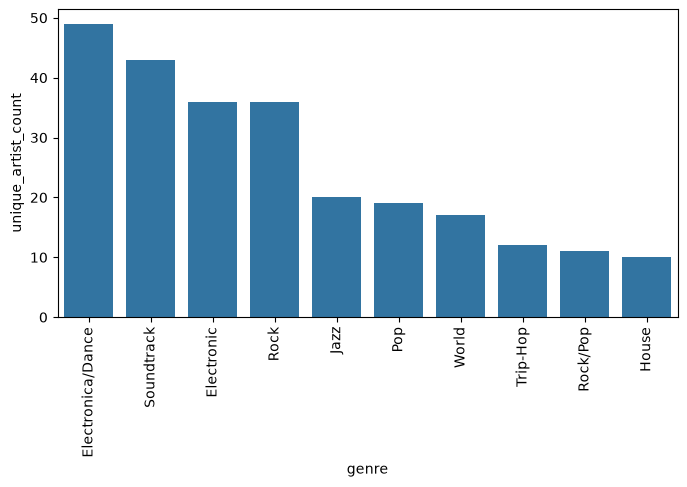

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

sns.barplot(data = artist_by_genre.head(10), x = 'genre', y = 'unique_artist_count')
# Rotate the x-axis labels 90 degrees
plt.xticks(rotation=90)

plt.show()

In [ ]:
duration_per_genre = mp3.groupby(mp3['genre'])['duration_secs'].sum().reset_index(name='duration').sort_values(by ='duration', ascending = False)
duration_per_genre.columns = ['genre', 'duration']
duration_per_genre

,genre,duration
33,Electronica/Dance,30876.601256
29,Electronic,24753.125875
71,Rock,23164.026938
79,Soundtrack,20855.766174
53,Jazz,10820.608781
...,...,...
94,soundtrack,126.545125
14,Chanson,86.099592
87,Turntablism,51.546667
24,Drill & Bass,40.860875


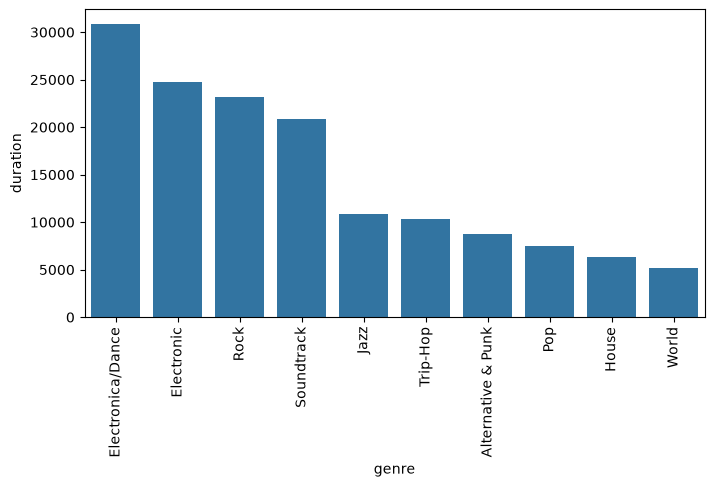

In [ ]:
plt.figure(figsize=(8, 4))

sns.barplot(data = duration_per_genre.head(10), x = 'genre', y = 'duration')
# Rotate the x-axis labels 90 degrees
plt.xticks(rotation=90)

plt.show()